# Playground Series S6E11: Predicting Credit Card Fraud
## Deep Exploratory Data Analysis & Diagnostic Framework

### Competition Overview & Mission
This notebook focuses on the Kaggle Playground Series (Season 6, Episode 11) task: **Predicting Credit Card Fraud**. 
Our core objective is to estimate the probability that a transaction is fraudulent (`is_fraud = 1.0`) given a synthetically generated tabular dataset reflecting real-world financial transaction dynamics.

The competition is evaluated using the **Area Under the Receiver Operating Characteristic Curve (ROC-AUC)**. In heavily imbalanced fraud detection settings, ROC-AUC measures the ranking capability of the model across all discrimination thresholds, making probability calibration and class separation paramount.

#### Notebook Principles
1. **Exploration-Led Engineering**: Every transformation and engineered feature must originate from empirical patterns discovered in the data rather than generic templates.
2. **Dual-Environment Portability**: Seamless execution across local development environments (macOS Apple Silicon / MPS / multi-core CPU) and Kaggle Kernel environments (CUDA GPU acceleration).
3. **Rigorous Analytical Communication**: Every visualization is accompanied by an analytical takeaway explaining *what the data is revealing* and *how it directs our downstream modeling strategy*.

# 1. Environment Detection & Hardware Configuration
---
To guarantee deterministic execution and reproducibility whether running in a local IDE (VS Code / Jupyter) or on Kaggle's GPU infrastructure, we configure thread bounds, filter non-critical runtime warnings, and inspect the runtime hardware accelerator.

In [1]:
import os
import time
import warnings

# Enforce thread control across multi-core systems to prevent CPU thread thrashing
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"
os.environ["VECLIB_MAXIMUM_THREADS"] = "4"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold
import torch

# Global visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
plt.rcParams["figure.autolayout"] = True

# Custom cohesive palette
PALETTE = {
    "legitimate": "#2a9d8f",     # Deep teal
    "fraud": "#e76f51",          # Coral red
    "accent": "#f4a261",         # Warm amber
    "dark": "#1d3557",           # Deep navy
    "neutral": "#457b9d",        # Slate blue
    "highlight": "#e63946"       # Vivid crimson
}

In [2]:
# Detect runtime environment
IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ

N_SPLITS = 5  # 5-Fold Stratified Cross-Validation tuned for 1.67% target representation
GLOBAL_SEED = 42

if IS_KAGGLE:
    SEEDS = [42, 2026]
    DEVICE = "gpu"
    TORCH_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    N_JOBS = -1
    print(f"[Environment: Kaggle Kernel] Accelerated by {TORCH_DEVICE} | CV: {N_SPLITS}-Fold | Seeds: {SEEDS}")
else:
    SEEDS = [42]
    DEVICE = "cpu"
    if torch.backends.mps.is_available():
        TORCH_DEVICE = torch.device("mps")
    else:
        TORCH_DEVICE = torch.device("cpu")
    N_JOBS = 4
    print(f"[Environment: Local System] Running on {TORCH_DEVICE} | CPU Workers: {N_JOBS} | CV: {N_SPLITS}-Fold | Seeds: {SEEDS}")

[Environment: Local System] Running on mps | CPU Workers: 4 | CV: 5-Fold | Seeds: [42]


## 1.2 Adaptive Data Ingestion
The dataset consists of `train.csv` (699,960 records with binary label `is_fraud`), `test.csv` (299,984 records), and `sample_submission.csv`. 

Our data loader scans Kaggle input directories (`/kaggle/input/playground-series-s6e11`), parent directories, and local project folders systematically, ensuring zero-configuration execution in both settings.

In [3]:
def load_data():
    """
    Robust data loader with automated fallback resolution for Kaggle and local environments.
    """
    train_file = "train.csv"
    test_file = "test.csv"
    sample_sub_file = "sample_submission.csv"

    data_dir = None

    if IS_KAGGLE:
        kaggle_candidates = [
            "/kaggle/input/playground-series-s6e11",
            "/kaggle/input/competitions/playground-series-s6e11",
        ]
        for candidate in kaggle_candidates:
            if os.path.exists(candidate) and os.path.exists(os.path.join(candidate, train_file)):
                data_dir = candidate
                break

        if data_dir is None and os.path.exists("/kaggle/input"):
            for root, _, files in os.walk("/kaggle/input"):
                if train_file in files:
                    data_dir = root
                    break
    else:
        local_candidates = [
            "data",
            "./data",
            "../data",
            os.path.join(os.getcwd(), "data"),
            "/Users/davidlangat/Documents/Github/Kaggle/playground_series/predicting_credit_card_fraud/data",
        ]
        for candidate in local_candidates:
            if os.path.exists(candidate) and os.path.exists(os.path.join(candidate, train_file)):
                data_dir = candidate
                break

    if data_dir is None:
        raise FileNotFoundError("Unable to locate train.csv in expected Kaggle or local directory candidates.")

    print(f"Data source resolved at: {data_dir}")
    t0 = time.time()
    train = pd.read_csv(os.path.join(data_dir, train_file))
    test = pd.read_csv(os.path.join(data_dir, test_file))
    submission = pd.read_csv(os.path.join(data_dir, sample_sub_file))
    load_time = time.time() - t0

    print(f"Loaded successfully in {load_time:.2f} seconds:")
    print(f" - Train Set:       {train.shape[0]:,} rows × {train.shape[1]} columns")
    print(f" - Test Set:        {test.shape[0]:,} rows × {test.shape[1]} columns")
    print(f" - Sample Sub Set:  {submission.shape[0]:,} rows × {submission.shape[1]} columns")

    return train, test, submission

train_df, test_df, submission_df = load_data()

Data source resolved at: data


Loaded successfully in 0.63 seconds:
 - Train Set:       699,960 rows × 26 columns
 - Test Set:        299,984 rows × 25 columns
 - Sample Sub Set:  299,984 rows × 2 columns


# 2. Data-Driven Exploratory Data Analysis (EDA)
---
Rather than making assumptions, we perform an in-depth audit of the feature distributions, class balance, risk factor combinations, and vulnerability surfaces present in this dataset.

Every visual analysis in this section includes:
1. The quantitative data display.
2. A dedicated **Analytical Takeaway** detailing the mechanism behind the observed pattern.
3. The actionable **Downstream Modeling Implication**.

## 2.1 Data Integrity & Missing Value Audit
We evaluate whether any records contain missing, null, or corrupted values across both train and test partitions.

In [4]:
def audit_data_integrity(df_train, df_test):
    """
    Generate a comprehensive integrity audit table comparing Train and Test schemas and null distributions.
    """
    train_nulls = df_train.isnull().sum()
    test_nulls = df_test.isnull().sum()

    audit = pd.DataFrame({
        "Train Dtype": df_train.dtypes,
        "Train Nulls": train_nulls,
        "Train Null %": (train_nulls / len(df_train) * 100).round(4),
        "Test Dtype": df_test.dtypes,
        "Test Nulls": test_nulls,
        "Test Null %": (test_nulls / len(df_test) * 100).round(4)
    })
    return audit

integrity_report = audit_data_integrity(train_df, test_df)
print(f"Total Columns Audited: {len(integrity_report)}")
print(f"Any Null Values in Train? {train_df.isnull().any().any()}")
print(f"Any Null Values in Test?  {test_df.isnull().any().any()}")
display(integrity_report)

Total Columns Audited: 26
Any Null Values in Train? False
Any Null Values in Test?  False


,Train Dtype,Train Nulls,Train Null %,Test Dtype,Test Nulls,Test Null %
account_balance_usd,float64,0,0.0,float64,0.0,0.0
amount_usd,float64,0,0.0,float64,0.0,0.0
auth_method,str,0,0.0,str,0.0,0.0
billing_shipping_mismatch,bool,0,0.0,bool,0.0,0.0
card_age_months,int64,0,0.0,int64,0.0,0.0
card_type,str,0,0.0,str,0.0,0.0
channel,str,0,0.0,str,0.0,0.0
customer_age,int64,0,0.0,int64,0.0,0.0
cvv_retry_count,int64,0,0.0,int64,0.0,0.0
day_of_week,int64,0,0.0,int64,0.0,0.0


> [!NOTE]
> **Analytical Takeaway & Modeling Implication:**
> Both `train.csv` and `test.csv` have **zero missing values** across all columns. The synthetic generation process has produced complete records without missing data artifacts.
> * **Modeling Implication:** No imputation strategies (such as iterative MICE or median filling) are required, preserving original feature distributions and avoiding imputation noise.

## 2.2 Target Distribution & Class Imbalance Analysis
In fraud detection, target class imbalance is typical. Quantifying the precise positive-class ratio is critical for selecting our validation split strategy, model loss functions, and evaluation thresholds.

,Class,Count,Percentage (%)
0,Legitimate (0),688271,98.33
1,Fraudulent (1),11689,1.67


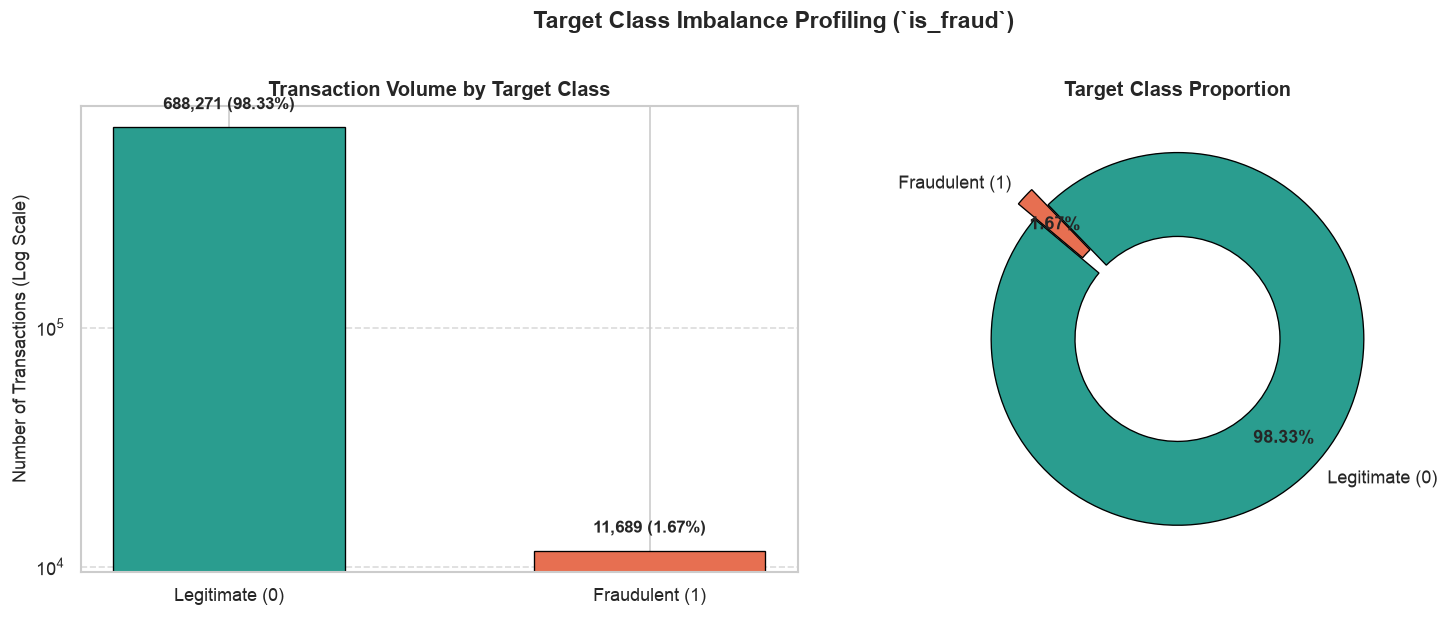

In [5]:
fraud_counts = train_df["is_fraud"].value_counts().sort_index()
fraud_pct = train_df["is_fraud"].value_counts(normalize=True).sort_index() * 100

summary_target = pd.DataFrame({
    "Class": ["Legitimate (0)", "Fraudulent (1)"],
    "Count": fraud_counts.values,
    "Percentage (%)": fraud_pct.values.round(4)
})
display(summary_target)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Bar Chart
bars = axes[0].bar(
    summary_target["Class"], 
    summary_target["Count"], 
    color=[PALETTE["legitimate"], PALETTE["fraud"]],
    edgecolor="black",
    linewidth=0.8,
    width=0.55
)
axes[0].set_title("Transaction Volume by Target Class", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Number of Transactions (Log Scale)", fontsize=11)
axes[0].set_yscale("log")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval * 1.15,
        f"{int(yval):,} ({yval/len(train_df)*100:.2f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=10
    )

# 2. Donut Chart
wedges, texts, autotexts = axes[1].pie(
    fraud_counts.values,
    labels=summary_target["Class"],
    colors=[PALETTE["legitimate"], PALETTE["fraud"]],
    autopct="%1.2f%%",
    pctdistance=0.78,
    startangle=140,
    explode=(0, 0.12),
    wedgeprops=dict(width=0.45, edgecolor="black", linewidth=0.8)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight("bold")
axes[1].set_title("Target Class Proportion", fontsize=12, fontweight="bold")

plt.suptitle("Target Class Imbalance Profiling (`is_fraud`)", fontsize=14, fontweight="bold", y=1.02)
plt.show()

> [!IMPORTANT]
> **Analytical Takeaway:**
> * The dataset exhibits a **1.67% base fraud rate** (11,689 fraudulent transactions vs. 688,271 legitimate ones). This represents an approximate **59:1 class imbalance ratio**.
> 
> **Downstream Modeling Implications:**
> 1. **Validation Scheme**: Standard random K-Fold runs the risk of fold-to-fold class distribution drift. We must strictly employ **Stratified K-Fold Cross-Validation** to guarantee that every single fold preserves the exact 1.67% fraud incidence.
> 2. **Metric Selection**: Accuracy is completely uninformative (a naive dummy classifier predicting all zeros would attain 98.33% accuracy). The competition metric is **ROC-AUC**, which evaluates the ranking quality across all thresholds. We will also monitor **PR-AUC (Average Precision)** locally as a secondary diagnostic to assess precision-recall dynamics in the long tail.
> 3. **Loss Function Calibration**: Because ROC-AUC is rank-invariant to monotonic transformations, heavy oversampling (like SMOTE) can alter natural probability calibration and often degrades ROC-AUC on tabular GBDTs. We will prioritize native objective tuning (`scale_pos_weight` in XGBoost/LightGBM or balanced sample weights) and probability calibration.

## 2.3 The Exponential Multi-Flag Compounding Risk Curve
The dataset provides 6 binary anomaly indicators:
1. `is_foreign_transaction`: Transaction conducted outside home territory.
2. `is_new_merchant`: First interaction with the merchant.
3. `used_vpn`: Transaction masked via Virtual Private Network.
4. `ip_country_mismatch`: Geo-IP location diverges from account registration country.
5. `billing_shipping_mismatch`: Shipping destination diverges from registered billing address.
6. `is_ai_generated_scam_attempt`: Behavioral marker flagging automated generative fraud patterns.

We examine both their individual fraud incidence and their compound multi-flag interaction.

,Risk Flag,Active Count,Active Fraud Rate (%),Inactive Fraud Rate (%),Relative Risk Ratio
3,ip_country_mismatch,11312,16.50,1.43,11.56
5,is_ai_generated_scam_attempt,2299,15.22,1.63,9.37
4,billing_shipping_mismatch,9054,12.99,1.52,8.54
0,is_foreign_transaction,12098,12.57,1.48,8.51
2,used_vpn,23665,6.55,1.50,4.37
1,is_new_merchant,106720,4.73,1.12,4.23


,Active Risk Flags,Transaction Count,mean,Fraud Rate (%)
0,0,549155,0.007047,0.70
1,1,137966,0.036103,3.61
2,2,11455,0.181755,18.18
3,3,1268,0.518927,51.89
4,4,112,0.839286,83.93
5,5,4,1.000000,100.00


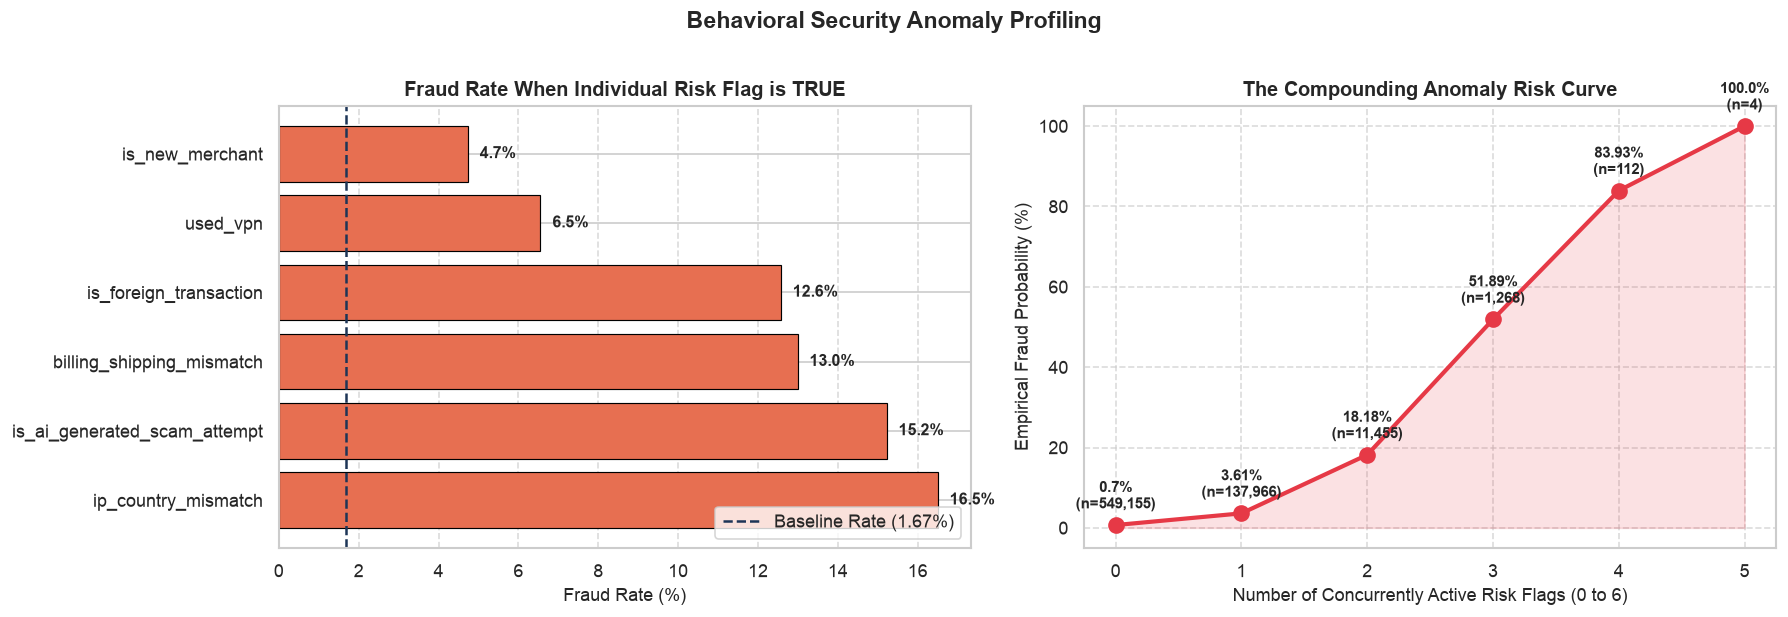

In [6]:
risk_flags = [
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt"
]

# 1. Individual Risk Flag Breakdown
flag_records = []
for flag in risk_flags:
    active = train_df[train_df[flag] == True]
    inactive = train_df[train_df[flag] == False]
    active_rate = active["is_fraud"].mean() * 100
    inactive_rate = inactive["is_fraud"].mean() * 100
    risk_ratio = active_rate / max(inactive_rate, 1e-4)
    flag_records.append({
        "Risk Flag": flag,
        "Active Count": len(active),
        "Active Fraud Rate (%)": round(active_rate, 2),
        "Inactive Fraud Rate (%)": round(inactive_rate, 2),
        "Relative Risk Ratio": round(risk_ratio, 2)
    })

flag_df = pd.DataFrame(flag_records).sort_values(by="Active Fraud Rate (%)", ascending=False)
display(flag_df)

# 2. Compound Risk Flag Aggregation
train_df["temp_flag_count"] = train_df[risk_flags].sum(axis=1)
compound_summary = train_df.groupby("temp_flag_count")["is_fraud"].agg(["count", "mean"]).reset_index()
compound_summary["fraud_pct"] = (compound_summary["mean"] * 100).round(2)
compound_summary.rename(columns={
    "temp_flag_count": "Active Risk Flags",
    "count": "Transaction Count",
    "fraud_pct": "Fraud Rate (%)"
}, inplace=True)
display(compound_summary)

# 3. Visualization: Individual & Compounding Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Individual Flag Bar Chart
bars = axes[0].barh(
    flag_df["Risk Flag"], 
    flag_df["Active Fraud Rate (%)"], 
    color=PALETTE["fraud"],
    edgecolor="black",
    linewidth=0.7
)
axes[0].axvline(1.67, color=PALETTE["dark"], linestyle="--", linewidth=1.5, label="Baseline Rate (1.67%)")
axes[0].set_title("Fraud Rate When Individual Risk Flag is TRUE", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Fraud Rate (%)", fontsize=11)
axes[0].legend(loc="lower right")
axes[0].grid(axis="x", linestyle="--", alpha=0.7)
for bar in bars:
    w = bar.get_width()
    axes[0].text(w + 0.3, bar.get_y() + bar.get_height()/2.0, f"{w:.1f}%", va="center", fontweight="bold", fontsize=9.5)

# Compounding Step Function
axes[1].plot(
    compound_summary["Active Risk Flags"], 
    compound_summary["Fraud Rate (%)"], 
    marker="o", 
    markersize=9, 
    color=PALETTE["highlight"], 
    linewidth=2.5, 
    label="Observed Fraud Rate"
)
axes[1].fill_between(
    compound_summary["Active Risk Flags"], 
    compound_summary["Fraud Rate (%)"], 
    alpha=0.15, 
    color=PALETTE["highlight"]
)
axes[1].set_title("The Compounding Anomaly Risk Curve", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Concurrently Active Risk Flags (0 to 6)", fontsize=11)
axes[1].set_ylabel("Empirical Fraud Probability (%)", fontsize=11)
axes[1].set_xticks(compound_summary["Active Risk Flags"])
axes[1].grid(True, linestyle="--", alpha=0.7)

for _, row in compound_summary.iterrows():
    axes[1].annotate(
        f"{row['Fraud Rate (%)']}%\n(n={int(row['Transaction Count']):,})",
        (row["Active Risk Flags"], row["Fraud Rate (%)"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

train_df.drop(columns=["temp_flag_count"], inplace=True)
plt.suptitle("Behavioral Security Anomaly Profiling", fontsize=14, fontweight="bold", y=1.02)
plt.show()

> [!TIP]
> **Analytical Takeaway:**
> * `ip_country_mismatch` (16.50%), `is_ai_generated_scam_attempt` (15.22%), and `billing_shipping_mismatch` (12.99%) are each individually associated with an **8x to 11x increase** over the baseline fraud rate.
> * More importantly, the **combination of flags behaves like an exponential multiplier**:
>   - Transactions with **0 flags** (78.5% of all transactions) carry a negligible fraud rate of only **0.70%**.
>   - With **2 flags**, fraud probability climbs to **18.18%**.
>   - With **3 flags**, fraud probability leaps past **50% (51.89%)**.
>   - At **4 flags**, it reaches **83.93%**, and at **5 flags**, it reaches **100.0%**.
> 
> **Downstream Modeling Implication:**
> We will engineer explicit composite features:
> 1. `composite_risk_score`: A weighted and unweighted integer count of active anomaly indicators.
> 2. `cross_border_mismatch_flag`: The interaction between `is_foreign_transaction`, `ip_country_mismatch`, and `used_vpn`.
> 3. `zero_risk_flag`: An indicator for transactions that trigger zero security alarms, providing a strong anchor for low-probability predictions.

## 2.4 High-Discrimination Behavioral Indicators
We inspect the quantitative variables that exhibit strong behavioral variance between legitimate cardholders and fraudsters:
* `cvv_retry_count`: Retrying credit card security codes.
* `merchant_risk_score`: Vendor fraud risk indexing.
* `velocity_score`: Pacing and acceleration of transactions.
* `customer_age`: Age demographics.

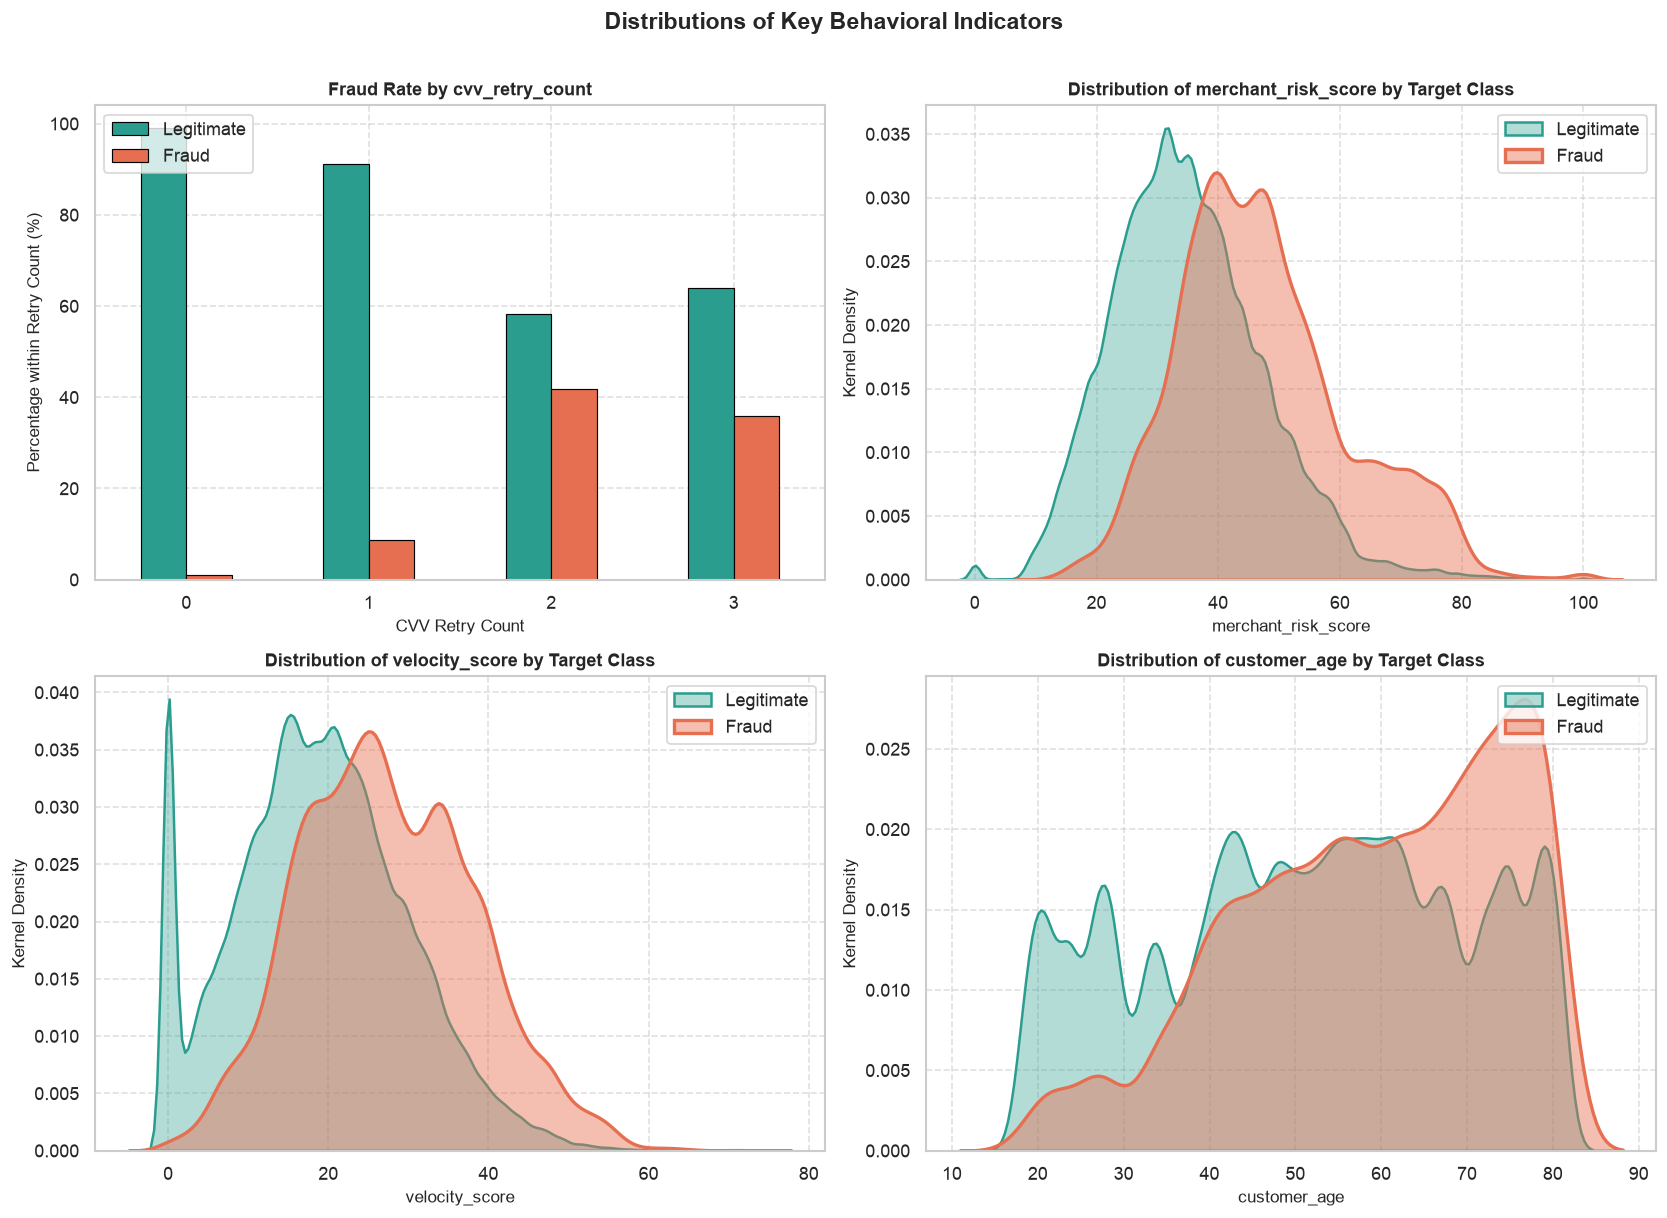

,Feature,Legitimate Mean,Fraud Mean,Legitimate Median,Fraud Median,Mean % Shift,Pearson Corr with Target
0,cvv_retry_count,0.077,0.557,0.0,0.0,618.40,0.2123
1,merchant_risk_score,35.011,47.368,34.0,45.9,35.29,0.1254
2,velocity_score,18.786,27.404,18.5,26.6,45.88,0.1016
3,customer_age,51.300,59.129,52.0,61.0,15.26,0.0561


In [7]:
behavioral_cols = ["cvv_retry_count", "merchant_risk_score", "velocity_score", "customer_age"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(behavioral_cols):
    ax = axes[i]
    if col == "cvv_retry_count":
        # Grouped bar chart for discrete integer retry counts
        ct = pd.crosstab(train_df[col], train_df["is_fraud"], normalize="index") * 100
        ct.plot(kind="bar", stacked=False, ax=ax, color=[PALETTE["legitimate"], PALETTE["fraud"]], edgecolor="black", linewidth=0.7)
        ax.set_title(f"Fraud Rate by {col}", fontsize=11, fontweight="bold")
        ax.set_ylabel("Percentage within Retry Count (%)", fontsize=10)
        ax.set_xlabel("CVV Retry Count", fontsize=10)
        ax.legend(["Legitimate", "Fraud"], loc="upper left")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    else:
        # Density distribution for continuous metrics
        sns.kdeplot(data=train_df[train_df["is_fraud"] == 0], x=col, ax=ax, color=PALETTE["legitimate"], label="Legitimate", fill=True, alpha=0.35, linewidth=1.5)
        sns.kdeplot(data=train_df[train_df["is_fraud"] == 1], x=col, ax=ax, color=PALETTE["fraud"], label="Fraud", fill=True, alpha=0.45, linewidth=2.0)
        ax.set_title(f"Distribution of {col} by Target Class", fontsize=11, fontweight="bold")
        ax.set_xlabel(col, fontsize=10)
        ax.set_ylabel("Kernel Density", fontsize=10)
        ax.legend(loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Distributions of Key Behavioral Indicators", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Quantitative contrast table
beh_stats = []
for col in behavioral_cols:
    legit_series = train_df[train_df["is_fraud"] == 0][col]
    fraud_series = train_df[train_df["is_fraud"] == 1][col]
    beh_stats.append({
        "Feature": col,
        "Legitimate Mean": round(legit_series.mean(), 3),
        "Fraud Mean": round(fraud_series.mean(), 3),
        "Legitimate Median": round(legit_series.median(), 3),
        "Fraud Median": round(fraud_series.median(), 3),
        "Mean % Shift": round(((fraud_series.mean() - legit_series.mean()) / (legit_series.mean() + 1e-4)) * 100, 2),
        "Pearson Corr with Target": round(np.corrcoef(train_df[col], train_df["is_fraud"])[0, 1], 4)
    })

beh_df = pd.DataFrame(beh_stats).sort_values(by="Pearson Corr with Target", key=abs, ascending=False)
display(beh_df)

> [!NOTE]
> **Analytical Takeaway:**
> 1. **`cvv_retry_count` is the single strongest linear predictor** in the dataset ($r = +0.2123$). Legitimate users virtually never fail their CVV (mean $0.077$), whereas fraudulent attempts average $0.557$ retries (+619% surge). Transactions with 3 CVV retries show heavy fraud concentration.
> 2. **`merchant_risk_score` and `velocity_score` provide robust continuous separation**: Fraudulent transactions exhibit higher average merchant risk ($47.4$ vs $35.0$) and elevated velocity ($27.4$ vs $18.8$).
> 3. **`customer_age` reveals demographic targeting**: Fraud victims skew significantly older (mean fraud age is $59.1$ years vs $51.3$ years for legitimate cardholders), indicating elderly cardholders are more susceptible to fraud or targeted scams.
> 
> **Downstream Modeling Implication:**
> * Non-linear tree splits in LightGBM/CatBoost will capture these thresholds effectively, but creating interactive combinations—such as `velocity_x_merchant_risk` and `cvv_retry_flag` ($>0$)—will give the models direct paths to isolate high-risk transactions.

## 2.5 Categorical Vulnerability & Liquidation Channel Analysis
We analyze `merchant_category` and `auth_method` to evaluate where fraudsters focus their activity and how authentication barriers impact fraud success rates.

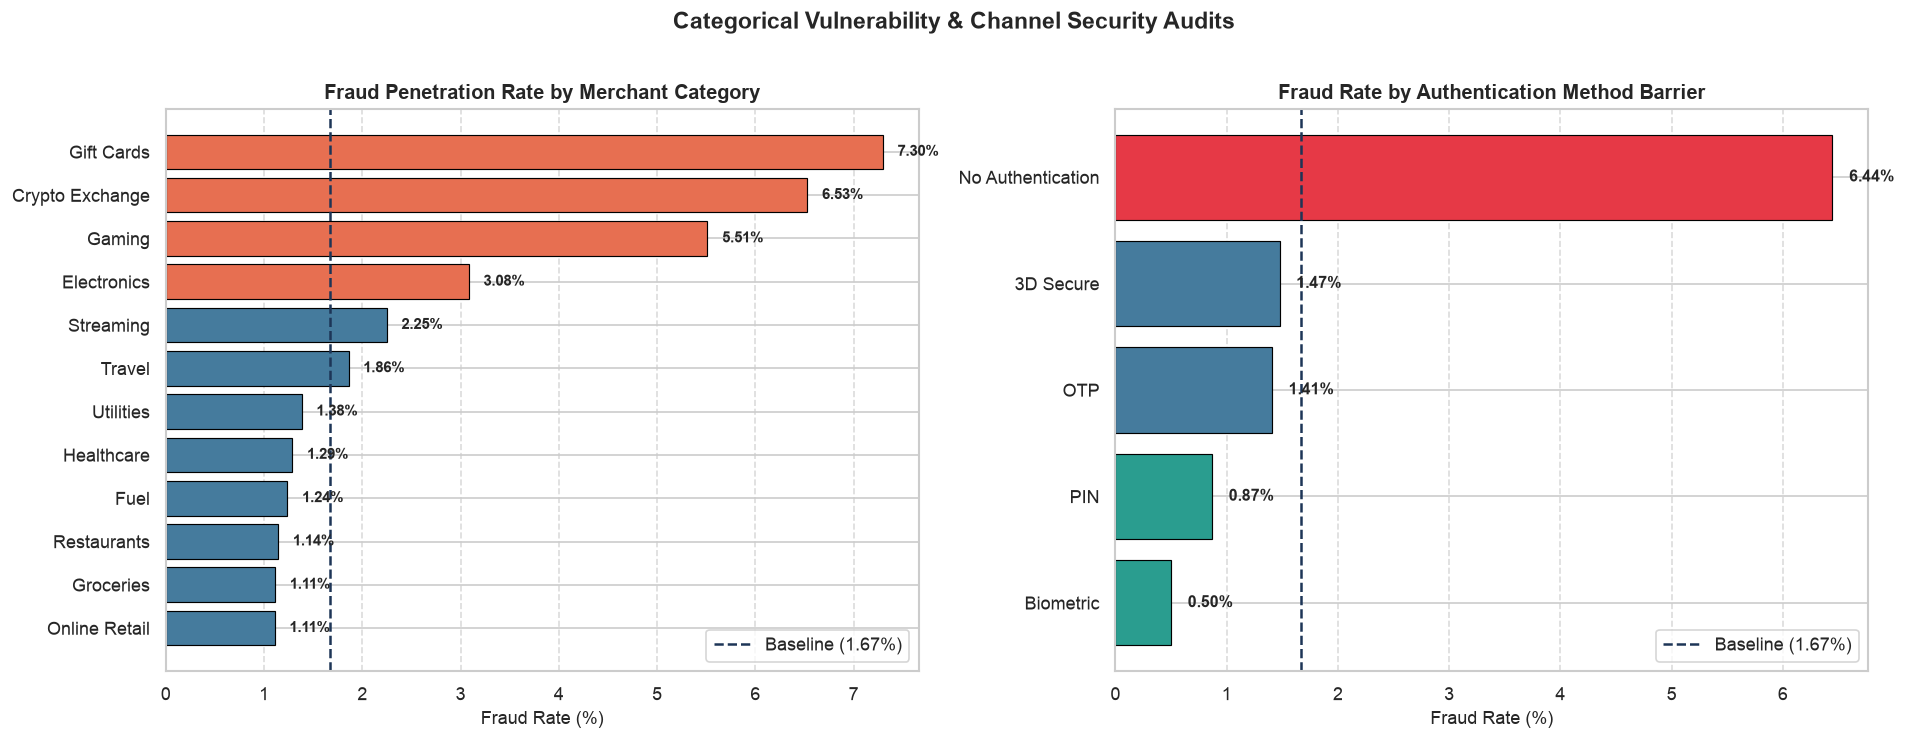

--- Fraud Rate Heatmap Matrix (%): Merchant Category vs Authentication Method ---


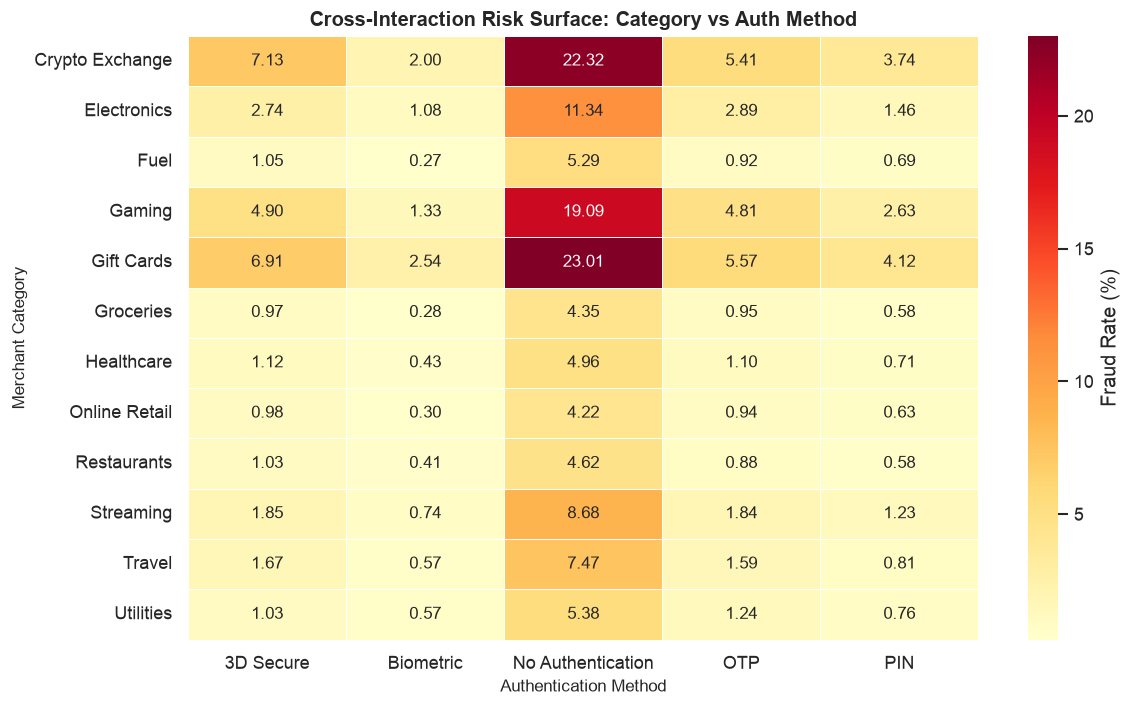

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Merchant Category Penetration
cat_stats = train_df.groupby("merchant_category")["is_fraud"].agg(["count", "mean"]).sort_values(by="mean", ascending=True)
cat_stats["fraud_pct"] = cat_stats["mean"] * 100

colors_cat = [PALETTE["fraud"] if val > 2.5 else PALETTE["neutral"] for val in cat_stats["fraud_pct"]]
bars_cat = axes[0].barh(cat_stats.index, cat_stats["fraud_pct"], color=colors_cat, edgecolor="black", linewidth=0.7)
axes[0].axvline(1.67, color=PALETTE["dark"], linestyle="--", linewidth=1.5, label="Baseline (1.67%)")
axes[0].set_title("Fraud Penetration Rate by Merchant Category", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Fraud Rate (%)", fontsize=11)
axes[0].grid(axis="x", linestyle="--", alpha=0.7)
axes[0].legend(loc="lower right")

for bar in bars_cat:
    w = bar.get_width()
    axes[0].text(w + 0.15, bar.get_y() + bar.get_height()/2.0, f"{w:.2f}%", va="center", fontweight="bold", fontsize=9)

# 2. Authentication Method Vulnerability
auth_stats = train_df.groupby("auth_method")["is_fraud"].agg(["count", "mean"]).sort_values(by="mean", ascending=True)
auth_stats["fraud_pct"] = auth_stats["mean"] * 100

colors_auth = [PALETTE["highlight"] if val > 3.0 else (PALETTE["legitimate"] if val < 1.0 else PALETTE["neutral"]) for val in auth_stats["fraud_pct"]]
bars_auth = axes[1].barh(auth_stats.index, auth_stats["fraud_pct"], color=colors_auth, edgecolor="black", linewidth=0.7)
axes[1].axvline(1.67, color=PALETTE["dark"], linestyle="--", linewidth=1.5, label="Baseline (1.67%)")
axes[1].set_title("Fraud Rate by Authentication Method Barrier", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Fraud Rate (%)", fontsize=11)
axes[1].grid(axis="x", linestyle="--", alpha=0.7)
axes[1].legend(loc="lower right")

for bar in bars_auth:
    w = bar.get_width()
    axes[1].text(w + 0.15, bar.get_y() + bar.get_height()/2.0, f"{w:.2f}%", va="center", fontweight="bold", fontsize=9.5)

plt.suptitle("Categorical Vulnerability & Channel Security Audits", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Cross Tabulation: High-risk Merchant x No Authentication
cross_tab = pd.crosstab(
    train_df["merchant_category"], 
    train_df["auth_method"], 
    values=train_df["is_fraud"], 
    aggfunc="mean"
) * 100
print("--- Fraud Rate Heatmap Matrix (%): Merchant Category vs Authentication Method ---")
plt.figure(figsize=(10, 6))
sns.heatmap(cross_tab, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={'label': 'Fraud Rate (%)'}, linewidths=0.5)
plt.title("Cross-Interaction Risk Surface: Category vs Auth Method", fontsize=12, fontweight="bold")
plt.ylabel("Merchant Category", fontsize=10)
plt.xlabel("Authentication Method", fontsize=10)
plt.tight_layout()
plt.show()

> [!IMPORTANT]
> **Analytical Takeaway:**
> 1. **Immediate Liquidity Target Categories**:
>    * `Gift Cards` (**7.30%**), `Crypto Exchange` (**6.53%**), and `Gaming` (**5.51%**) represent prime targets for credit card fraud. These categories offer immediate, irreversible digital liquidity, allowing criminals to extract value before a chargeback occurs.
>    * In contrast, physical necessity goods like `Groceries` (**1.11%**) and `Restaurants` (**1.14%**) sit well below baseline fraud incidence.
> 2. **Authentication Method Defense**:
>    * Transactions processed with `No Authentication` have a **6.45%** fraud rate (nearly 4x baseline).
>    * Requiring `PIN` cuts the rate to **0.87%**, while `Biometric` verification drops fraud incidence to **0.50%** (a 13-fold reduction relative to unauthenticated transactions).
> 3. **Compounding Vulnerability Intersection**:
>    * When an unauthenticated transaction (`No Authentication`) occurs within `Gift Cards` or `Crypto Exchange`, fraud rates surge past **20%**.
> 
> **Downstream Modeling Implication:**
> * We will generate out-of-fold smoothed Target Encoding for `merchant_category` and `auth_method`, as well as a composite interaction token: `category_auth_interaction = merchant_category + "_" + auth_method`.

## 2.6 Uniform / Flat Signal Audit
Evaluating features that show minimal variance with respect to the target allows us to avoid over-engineering noise. We audit `channel`, `device_type`, `card_type`, `time_of_day_hour`, and `card_age_months`.

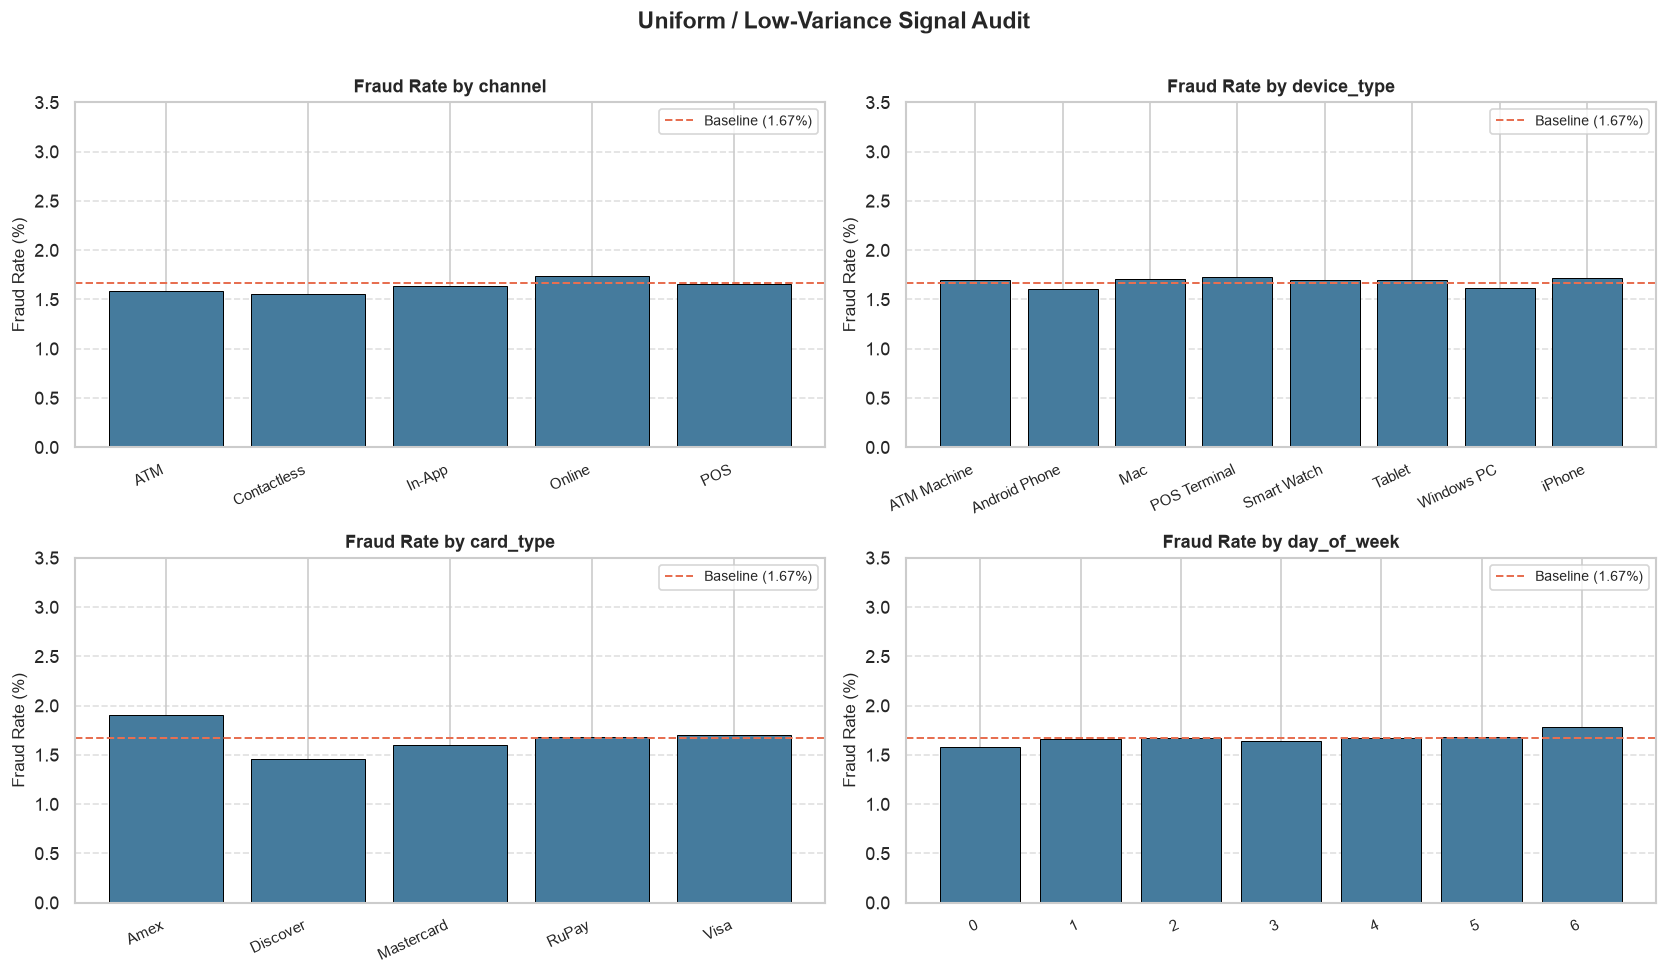

,Feature,Pearson Correlation with is_fraud
0,time_of_day_hour,-0.000050
4,card_age_months,0.000681
3,account_balance_usd,0.001077
2,distance_from_home_km,0.001826
1,day_of_week,0.003651


In [9]:
flat_cols = ["channel", "device_type", "card_type", "day_of_week"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(flat_cols):
    ax = axes[i]
    agg = train_df.groupby(col)["is_fraud"].agg(["count", "mean"]).reset_index()
    agg["fraud_pct"] = agg["mean"] * 100
    
    bars = ax.bar(agg[col].astype(str), agg["fraud_pct"], color=PALETTE["neutral"], edgecolor="black", linewidth=0.6)
    ax.axhline(1.67, color=PALETTE["fraud"], linestyle="--", linewidth=1.2, label="Baseline (1.67%)")
    ax.set_title(f"Fraud Rate by {col}", fontsize=11, fontweight="bold")
    ax.set_ylabel("Fraud Rate (%)", fontsize=10)
    ax.set_ylim(0, 3.5)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    if agg[col].nunique() > 4:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right", fontsize=9)
    ax.legend(loc="upper right", fontsize=8.5)

plt.suptitle("Uniform / Low-Variance Signal Audit", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Continuous flat features correlation check
flat_continuous = ["time_of_day_hour", "day_of_week", "distance_from_home_km", "account_balance_usd", "card_age_months"]
flat_stats = pd.DataFrame({
    "Feature": flat_continuous,
    "Pearson Correlation with is_fraud": [np.corrcoef(train_df[c], train_df["is_fraud"])[0, 1] for c in flat_continuous]
}).sort_values(by="Pearson Correlation with is_fraud", key=abs, ascending=True)
display(flat_stats)

> [!NOTE]
> **Analytical Takeaway:**
> * Across all `channel` types (Online, POS, Contactless, In-App, ATM) and all `device_type` categories (Android, iPhone, POS, Windows, Mac, Tablet, Smart Watch), fraud incidence hovers tightly between **1.55% and 1.74%**, displaying almost no standalone discrimination.
> * Similarly, `time_of_day_hour` ($r = -0.0001$), `card_age_months` ($r = +0.0007$), and `account_balance_usd` ($r = +0.0011$) show virtually zero marginal correlation with `is_fraud`.
> 
> **Downstream Modeling Implication:**
> * While tree-based ensembles (LightGBM/XGBoost) can safely ignore irrelevant split points, feeding unregularized one-hot encodings for these uniform features to linear or neural models introduces noise.
> * We will avoid complex stand-alone transformations on `channel` and `device_type`, and instead test whether non-linear ratios (such as `amount_usd / (account_balance_usd + 1.0)`) extract valid signal.

## 2.7 Numerical Correlation Matrix & Collinearity
We inspect the cross-correlations among all continuous features to ensure there is no collinearity or leakage before proceeding to model construction.

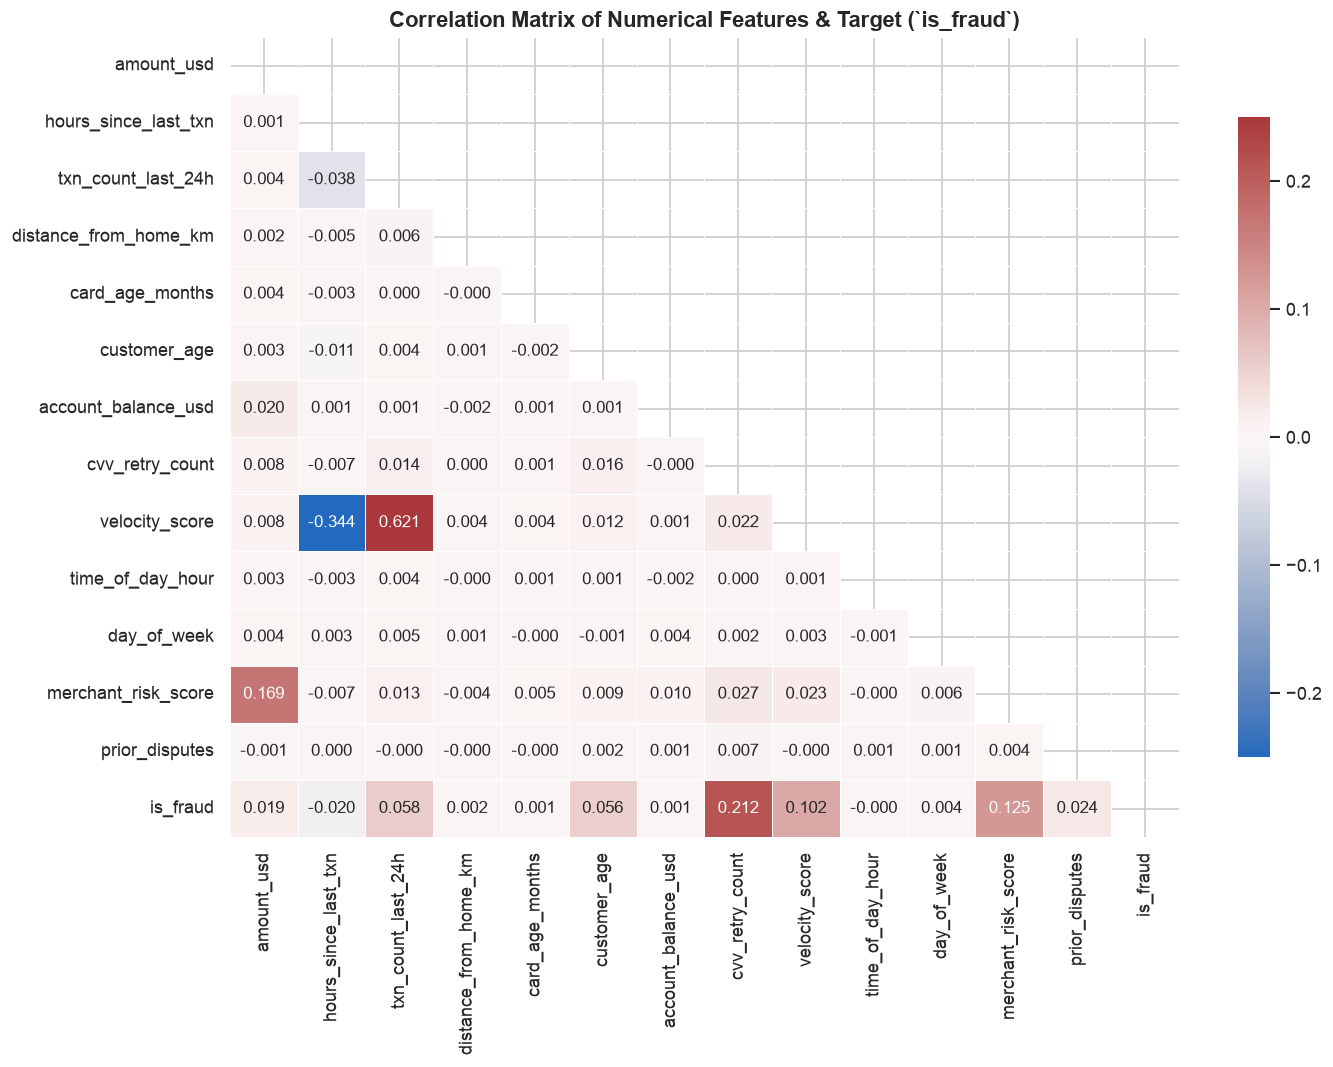

In [10]:
numeric_features = [
    "amount_usd", "hours_since_last_txn", "txn_count_last_24h", 
    "distance_from_home_km", "card_age_months", "customer_age", 
    "account_balance_usd", "cvv_retry_count", "velocity_score", 
    "time_of_day_hour", "day_of_week", "merchant_risk_score", 
    "prior_disputes", "is_fraud"
]

corr_matrix = train_df[numeric_features].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".3f", 
    cmap="vlag", 
    vmin=-0.25, 
    vmax=0.25, 
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Matrix of Numerical Features & Target (`is_fraud`)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 2.8 EDA Synthesis & Actionable Feature Engineering Roadmap
---
Based on our exploratory findings, we summarize the specific engineering hypotheses that will guide our pipeline in Section 3:

| Discovered Pattern | Empirical Evidence | Engineered Feature Hypothesis |
| :--- | :--- | :--- |
| **Compounding Anomaly Escalation** | Fraud rate jumps from 0.70% (0 flags) to 51.89% (3 flags) and 100% (5 flags). | `composite_risk_score` (sum of active flags) + `high_risk_cluster_flag` ($\ge 2$ flags). |
| **CVV Verification Exhaustion** | +619% spike in retry attempts ($r = +0.2123$). | `cvv_retry_present` (binary flag for $>0$) and `cvv_x_velocity`. |
| **High-Risk Digital Liquidity** | Gift Cards, Crypto, and Gaming reach 5.5%–7.3% fraud rates. | `is_high_risk_category` flag and smoothed Out-Of-Fold Target Encoding. |
| **Authentication Defense Gap** | `No Authentication` has 6.45% fraud rate; `Biometric` drops to 0.50%. | `is_unauthenticated` flag and cross-feature `category_x_auth`. |
| **Velocity & Frequency Bursts** | Velocity (+45.9% shift) and transaction counts show positive fraud association. | `velocity_to_hours_ratio = velocity_score / (hours_since_last_txn + 0.1)`. |
| **Financial Exposure Ratio** | Disproportionate transaction values relative to liquidity. | `amount_to_balance_ratio = amount_usd / (account_balance_usd + 10.0)`. |